In [3]:
# ===== Cell 1: Imports, device, global configuration =====
import os, json, math, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
torch.backends.cudnn.benchmark = True

# Save results to Google Drive so a Colab disconnect doesn't lose finished runs.
# Finished runs are cached as JSON files and skipped when you re-run a cell.
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTS_DIR = '/content/drive/MyDrive/rethinking_generalization_fig1'
else:
    RESULTS_DIR = '/content/fig1_results'
os.makedirs(RESULTS_DIR, exist_ok=True)

# --- Hyperparameters from Appendix A ---
MOMENTUM = 0.9
LR_DECAY_PER_EPOCH = 0.95
INIT_LR = {"inception": 0.1, "alexnet": 0.01, "mlp_1x512": 0.01}

# ASSUMPTION: the paper does not state the batch size.
BATCH_SIZE = 128

# Mixed precision, purely for speed on Colab GPUs (set False for full fp32).
USE_AMP = True
AMP_ENABLED = USE_AMP and device.type == "cuda"

NUM_CLASSES = 10

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Device: cuda Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# ===== Cell 2: Load CIFAR10 + preprocessing from Appendix A =====
import tarfile
import os

# Extract CIFAR-10 from Google Drive to avoid slow network downloads
local_tar = '/content/drive/MyDrive/cifar-10-python.tar.gz'
target_dir = '/content/data'
os.makedirs(target_dir, exist_ok=True)

if os.path.exists(local_tar):
    print(f"Extracting local dataset from {local_tar}...")
    with tarfile.open(local_tar, 'r:gz') as tar:
        tar.extractall(path=target_dir)
    print("Extraction complete.")
else:
    print(f"Warning: {local_tar} not found. Attempting standard download instead.")

train_set = torchvision.datasets.CIFAR10(root=target_dir, train=True,  download=True)
test_set  = torchvision.datasets.CIFAR10(root=target_dir, train=False, download=True)

def to_tensor01(arr):
    """uint8 [N,32,32,3] -> float [N,3,32,32] scaled into [0,1] (divide by 255)."""
    return torch.from_numpy(arr).permute(0, 3, 1, 2).float().div_(255.0)

def center_crop(x, size=28):
    """Crop from the center to get 28x28 inputs."""
    o = (x.shape[-1] - size) // 2
    return x[..., o:o + size, o:o + size].contiguous()

def per_image_whitening(x):
    """(x - mean) / adjusted_std, independently for each image,
    with adjusted_std = max(std, 1/sqrt(num_elements))."""
    n_el = x[0].numel()
    flat = x.reshape(x.shape[0], -1)
    mean = flat.mean(dim=1, keepdim=True)
    std = flat.std(dim=1, unbiased=False, keepdim=True)
    adj = torch.clamp(std, min=1.0 / math.sqrt(n_el))
    return ((flat - mean) / adj).reshape_as(x)

# Cropped (not yet whitened) images, kept on CPU.
X_TRAIN_RAW = center_crop(to_tensor01(train_set.data))   # [50000, 3, 28, 28]
X_TEST_RAW  = center_crop(to_tensor01(test_set.data))    # [10000, 3, 28, 28]
Y_TRAIN_TRUE = torch.tensor(train_set.targets, dtype=torch.long)
Y_TEST       = torch.tensor(test_set.targets,  dtype=torch.long)

print(X_TRAIN_RAW.shape, X_TEST_RAW.shape)

Extracting local dataset from /content/drive/MyDrive/cifar-10-python.tar.gz...


/tmp/ipykernel_2489/2587411972.py:13: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=target_dir)


Extraction complete.
torch.Size([50000, 3, 28, 28]) torch.Size([10000, 3, 28, 28])


In [5]:
# ===== Cell 3: Data modifications from Section 2.1 =====

def corrupt_labels(y, p, seed):
    """Partially corrupted labels: independently with probability p, the label of
    each image is replaced by a uniform random class. p = 1 gives fully random labels.
    The random labels are generated once, so they stay consistent across epochs."""
    g = torch.Generator().manual_seed(seed)
    y = y.clone()
    mask = torch.rand(len(y), generator=g) < p
    y[mask] = torch.randint(0, NUM_CLASSES, (int(mask.sum()),), generator=g)
    return y

def shuffle_pixels(x, perm):
    """Shuffled pixels: one fixed permutation of pixel locations, applied to every
    image in both training and test set.
    ASSUMPTION: a 'pixel' is a spatial location, so its RGB values move together."""
    N, C, H, W = x.shape
    return x.reshape(N, C, H * W)[:, :, perm].reshape(N, C, H, W)

def random_pixels(x, seed):
    """Random pixels: a different random permutation for each image independently."""
    g = torch.Generator().manual_seed(seed)
    N, C, H, W = x.shape
    perms = torch.argsort(torch.rand(N, H * W, generator=g), dim=1)
    idx = perms.unsqueeze(1).expand(N, C, H * W)
    return torch.gather(x.reshape(N, C, H * W), 2, idx).reshape(N, C, H, W)

# Per-channel mean/std of the original training images, used for the Gaussian setting.
DATA_MEAN = X_TRAIN_RAW.mean(dim=(0, 2, 3), keepdim=True)
DATA_STD  = X_TRAIN_RAW.std(dim=(0, 2, 3), keepdim=True)

def gaussian_images(shape, seed):
    """Gaussian: random pixels drawn from a Gaussian with the dataset's mean and variance."""
    g = torch.Generator().manual_seed(seed)
    return torch.randn(shape, generator=g) * DATA_STD + DATA_MEAN

def make_dataset(setting, p=0.0, seed=0):
    """Returns (x_train, y_train, x_test, y_test), whitened and on the GPU.
    The test labels are always the true labels.
    ASSUMPTION: for the input-corruption settings, the original training labels are kept."""
    xtr, xte, ytr = X_TRAIN_RAW, X_TEST_RAW, Y_TRAIN_TRUE
    if setting == 'true_labels':
        pass
    elif setting == 'partial':
        ytr = corrupt_labels(ytr, p, seed)
    elif setting == 'random_labels':
        ytr = corrupt_labels(ytr, 1.0, seed)
    elif setting == 'shuffled_pixels':
        perm = torch.randperm(28 * 28, generator=torch.Generator().manual_seed(seed))
        xtr, xte = shuffle_pixels(xtr, perm), shuffle_pixels(xte, perm)
    elif setting == 'random_pixels':
        xtr, xte = random_pixels(xtr, seed), random_pixels(xte, seed + 1)
    elif setting == 'gaussian':
        xtr, xte = gaussian_images(xtr.shape, seed), gaussian_images(xte.shape, seed + 1)
    else:
        raise ValueError(setting)
    xtr, xte = per_image_whitening(xtr), per_image_whitening(xte)
    return xtr.to(device), ytr.to(device), xte.to(device), Y_TEST.to(device)

In [6]:
# ===== Cell 4: Models =====

class ConvModule(nn.Module):
    """Figure 3: Convolution -> Batch Norm -> ReLU.
    The paper's Inception has 1,649,402 parameters. That count is matched exactly when
    the conv has no bias and BN has a learnable shift but no scale, so BN is built that way."""
    def __init__(self, cin, cout, k, stride=1):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, k, stride=stride, padding=k // 2, bias=False)
        self.bn = nn.BatchNorm2d(cout, affine=False)
        self.beta = nn.Parameter(torch.zeros(1, cout, 1, 1))
    def forward(self, x):
        return F.relu(self.bn(self.conv(x)) + self.beta)

class InceptionModule(nn.Module):
    """Figure 3: a 1x1 conv branch (ch1) and a 3x3 conv branch (ch3), concatenated in channels."""
    def __init__(self, cin, ch1, ch3):
        super().__init__()
        self.b1 = ConvModule(cin, ch1, 1)
        self.b3 = ConvModule(cin, ch3, 3)
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x)], dim=1)

class DownsampleModule(nn.Module):
    """Figure 3: a 3x3 conv with stride 2 (ch3) and a 3x3 max pool with stride 2, concatenated.
    ASSUMPTION: 'same' padding, so 28 -> 14 -> 7, matching the 7x7 global mean pool."""
    def __init__(self, cin, ch3):
        super().__init__()
        self.conv = ConvModule(cin, ch3, 3, stride=2)
        self.pool = nn.MaxPool2d(3, stride=2, padding=1)
    def forward(self, x):
        return torch.cat([self.conv(x), self.pool(x)], dim=1)

class SmallInception(nn.Module):
    """Figure 3 (right): the small Inception model for 28x28x3 inputs."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            ConvModule(3, 96, 3),            # 96 channels, 28x28
            InceptionModule(96, 32, 32),     # 64
            InceptionModule(64, 32, 48),     # 80
            DownsampleModule(80, 80),        # 160, 14x14
            InceptionModule(160, 112, 48),   # 160
            InceptionModule(160, 96, 64),    # 160
            InceptionModule(160, 80, 80),    # 160
            InceptionModule(160, 48, 96),    # 144
            DownsampleModule(144, 96),       # 240, 7x7
            InceptionModule(240, 176, 160),  # 336
            InceptionModule(336, 176, 160),  # 336
        )
        self.fc = nn.Linear(336, num_classes)
    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=(2, 3))               # 7x7 global mean pooling
        return self.fc(x)

class SmallAlexNet(nn.Module):
    """Appendix A: two (conv 5x5 -> max-pool 3x3 -> local response norm) modules,
    then fully connected layers of 384 and 192 units, then a 10-way linear layer.
    ASSUMPTION: 64 filters per conv layer and stride-2 'same' pooling (28 -> 14 -> 7).
    With these choices the parameter count is exactly the paper's 1,387,786.
    ASSUMPTION: the LRN constants are not stated, so the original AlexNet values are used."""
    def __init__(self, num_classes=10):
        super().__init__()
        lrn = lambda: nn.LocalResponseNorm(size=5, alpha=1e-4 * 5, beta=0.75, k=2.0)
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 5, padding=2), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1), lrn(),
            nn.Conv2d(64, 64, 5, padding=2), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1), lrn(),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 384), nn.ReLU(inplace=True),
            nn.Linear(384, 192), nn.ReLU(inplace=True),
            nn.Linear(192, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

class MLP(nn.Module):
    """'MLP 1x512' means one hidden layer with 512 hidden units."""
    def __init__(self, hidden=(512,), num_classes=10, in_dim=3 * 28 * 28):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(inplace=True)]
            d = h
        layers.append(nn.Linear(d, num_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def build_model(name):
    if name == 'inception': return SmallInception()
    if name == 'alexnet':   return SmallAlexNet()
    if name == 'mlp_1x512': return MLP((512,))
    raise ValueError(name)

# Sanity check against the parameter counts in Table 1.
expected = {'inception': 1_649_402, 'alexnet': 1_387_786, 'mlp_1x512': 1_209_866}
for name, exp in expected.items():
    n = sum(p.numel() for p in build_model(name).parameters())
    print(f"{name:10s}: {n:,} params (paper: {exp:,})")

inception : 1,649,402 params (paper: 1,649,402)
alexnet   : 1,387,786 params (paper: 1,387,786)
mlp_1x512 : 1,209,866 params (paper: 1,209,866)


In [7]:
# ===== Cell 5: Training / evaluation utilities =====

@torch.no_grad()
def evaluate(model, x, y, bs=1000):
    model.eval()
    correct, loss_sum = 0, 0.0
    for i in range(0, len(x), bs):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP_ENABLED):
            out = model(x[i:i + bs])
        loss_sum += F.cross_entropy(out.float(), y[i:i + bs], reduction='sum').item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return correct / len(x), loss_sum / len(x)

def train_run(model_name, data, max_steps=None, max_epochs=None,
              conv_acc=None, stop_acc=None, eval_each_epoch=True,
              log_every=100, seed=0, tag=""):
    """Trains one model.
    - Logs the average minibatch training loss every `log_every` steps (Fig. 1a).
    - If eval_each_epoch is True, measures full training-set accuracy after every epoch and
      records the first step at which it reaches conv_acc (time to overfit, Fig. 1b).
    - Stops at max_steps, at max_epochs, or when training accuracy reaches stop_acc.
    - Reports test accuracy at the end (Fig. 1c)."""
    set_seed(seed)
    xtr, ytr, xte, yte = data
    model = build_model(model_name).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=INIT_LR[model_name], momentum=MOMENTUM)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=LR_DECAY_PER_EPOCH)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED)

    n = len(xtr)
    step, epoch = 0, 0
    running = torch.zeros((), device=device)
    loss_steps, loss_vals, epoch_hist = [], [], []
    conv_step, train_acc = None, float('nan')
    t0, done = time.time(), False

    while not done:
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP_ENABLED):
                loss = F.cross_entropy(model(xtr[idx]), ytr[idx])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            step += 1
            running += loss.detach().float()
            if step % log_every == 0:
                loss_steps.append(step)
                loss_vals.append((running / log_every).item())
                running.zero_()
            if max_steps is not None and step >= max_steps:
                done = True
                break
        epoch += 1
        sched.step()   # decay factor 0.95 per training epoch

        msg = f"[{tag}] epoch {epoch:3d} step {step:6d} lr {sched.get_last_lr()[0]:.5f}"
        if loss_vals: msg += f" loss {loss_vals[-1]:.4f}"
        if eval_each_epoch:
            train_acc, _ = evaluate(model, xtr, ytr)   # accuracy on the (possibly corrupted) training labels
            epoch_hist.append((step, train_acc))
            if conv_acc is not None and conv_step is None and train_acc >= conv_acc:
                conv_step = step
            if stop_acc is not None and train_acc >= stop_acc:
                done = True
            msg += f" train_acc {train_acc:.4f}"
        if max_epochs is not None and epoch >= max_epochs:
            done = True
        print(msg + f" ({time.time() - t0:.0f}s)")

    if not eval_each_epoch:
        train_acc, _ = evaluate(model, xtr, ytr)
    test_acc, _ = evaluate(model, xte, yte)
    print(f"[{tag}] done: train_acc {train_acc:.4f}, test_acc {test_acc:.4f}, conv_step {conv_step}")
    return dict(model=model_name, loss_steps=loss_steps, loss_vals=loss_vals,
                epoch_hist=epoch_hist, conv_step=conv_step, final_step=step,
                train_acc=train_acc, test_acc=test_acc, steps_per_epoch=math.ceil(n / BATCH_SIZE))

In [8]:
# ===== Cell 6: Figure 1a experiments (Inception, five settings, 25k steps) =====
FIG1A_STEPS = 25_000
FIG1A_SETTINGS = ['true_labels', 'random_labels', 'shuffled_pixels', 'random_pixels', 'gaussian']

fig1a = {}
for s in FIG1A_SETTINGS:
    path = f'{RESULTS_DIR}/fig1a_{s}.json'
    if os.path.exists(path):
        fig1a[s] = json.load(open(path))
        print(f"loaded cached {s}")
        continue
    data = make_dataset(s, seed=123)
    r = train_run('inception', data, max_steps=FIG1A_STEPS, eval_each_epoch=False,
                  seed=0, tag=f"1a-{s}")
    json.dump(r, open(path, 'w'))
    fig1a[s] = r
    del data
    torch.cuda.empty_cache()

loaded cached true_labels
loaded cached random_labels
loaded cached shuffled_pixels
loaded cached random_pixels
loaded cached gaussian


In [9]:
# ===== Cell 7: Figure 1b/1c experiments (label corruption sweep) =====
CORRUPTIONS = [round(0.1 * i, 1) for i in range(11)]   # 0.0, 0.1, ..., 1.0 as in the figure
MODELS = ['inception', 'alexnet', 'mlp_1x512']

# ASSUMPTION: "time to overfit" is the first step at which full training-set accuracy
# reaches CONV_ACC. A run then continues until it reaches STOP_ACC (or MAX_EPOCHS),
# and its test error is measured. In Table 1, MLP/AlexNet top out at ~99.3-99.8% on
# random labels, so the convergence threshold is set slightly below 100%.
CONV_ACC = 0.99
STOP_ACC = 0.999
MAX_EPOCHS = 120

sweep = {m: {} for m in MODELS}
for m in MODELS:
    for p in CORRUPTIONS:
        path = f'{RESULTS_DIR}/fig1bc_{m}_p{p:.1f}.json'
        if os.path.exists(path):
            sweep[m][p] = json.load(open(path))
            print(f"loaded cached {m} p={p}")
            continue
        data = make_dataset('partial', p=p, seed=1000 + int(p * 10))
        r = train_run(m, data, max_epochs=MAX_EPOCHS, conv_acc=CONV_ACC, stop_acc=STOP_ACC,
                      eval_each_epoch=True, seed=0, tag=f"{m}-p{p:.1f}")
        json.dump(r, open(path, 'w'))
        sweep[m][p] = r
        del data
        torch.cuda.empty_cache()

loaded cached inception p=0.0
loaded cached inception p=0.1
loaded cached inception p=0.2
loaded cached inception p=0.3
loaded cached inception p=0.4
loaded cached inception p=0.5
loaded cached inception p=0.6
loaded cached inception p=0.7
loaded cached inception p=0.8
loaded cached inception p=0.9
loaded cached inception p=1.0
loaded cached alexnet p=0.0
loaded cached alexnet p=0.1
loaded cached alexnet p=0.2
loaded cached alexnet p=0.3
loaded cached alexnet p=0.4
loaded cached alexnet p=0.5
loaded cached alexnet p=0.6
loaded cached alexnet p=0.7
loaded cached alexnet p=0.8
loaded cached alexnet p=0.9
loaded cached alexnet p=1.0
loaded cached mlp_1x512 p=0.0
loaded cached mlp_1x512 p=0.1
loaded cached mlp_1x512 p=0.2
loaded cached mlp_1x512 p=0.3
loaded cached mlp_1x512 p=0.4
loaded cached mlp_1x512 p=0.5
loaded cached mlp_1x512 p=0.6
loaded cached mlp_1x512 p=0.7
loaded cached mlp_1x512 p=0.8
loaded cached mlp_1x512 p=0.9
loaded cached mlp_1x512 p=1.0


time-to-overfit ratio at p=1.0 for different loss thresholds:
  loss<=0.2: inception=5.31, alexnet=nan, mlp_1x512=2.92
  loss<=0.1: inception=4.29, alexnet=nan, mlp_1x512=nan
  loss<=0.05: inception=3.75, alexnet=nan, mlp_1x512=nan
  loss<=0.02: inception=3.41, alexnet=nan, mlp_1x512=nan


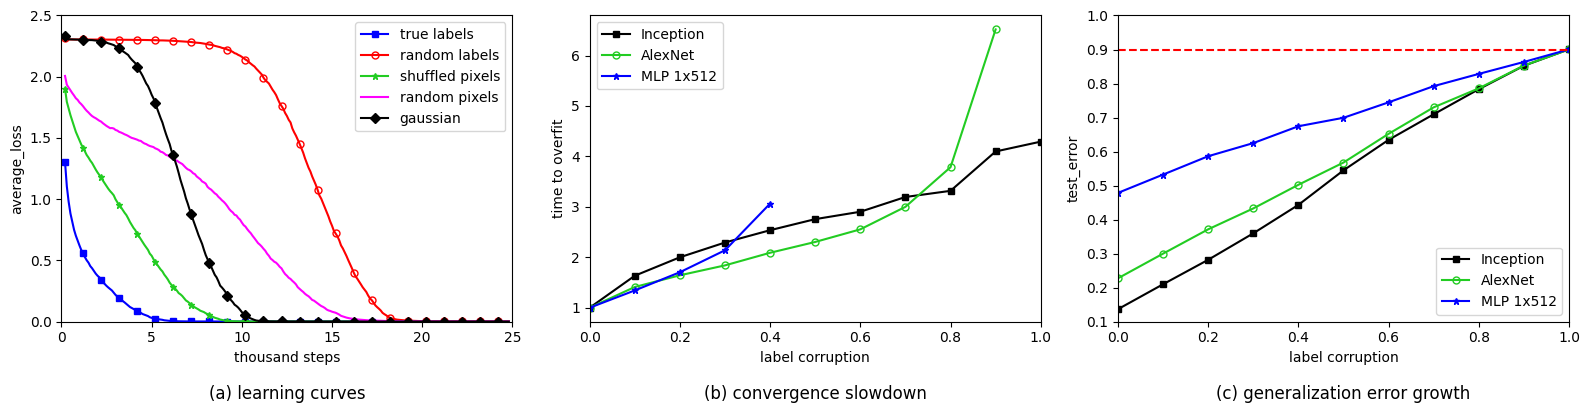

In [11]:
# ===== Cell 8: Plot Figure 1 =====
FIT_LOSS = 0.1   # ASSUMPTION: "time to overfit" = first step where the epoch-averaged training loss <= FIT_LOSS

def epoch_smooth(run):
    """Average the 100-step loss logs over a sliding window of ~1 epoch.
    This cancels the within-epoch sawtooth caused by reshuffling. Each point is
    placed at its window's center, so the curve is not shifted in time."""
    steps = np.asarray(run['loss_steps'], float)
    vals = np.asarray(run['loss_vals'], float)
    if len(steps) < 2:
        return steps, vals
    dt = steps[1] - steps[0]
    w = max(1, int(round(run['steps_per_epoch'] / dt)))
    if len(vals) < w:
        return steps, vals
    k = np.ones(w) / w
    return np.convolve(steps - dt / 2, k, 'valid'), np.convolve(vals, k, 'valid')

def time_to_fit(run, thresh=FIT_LOSS):
    """First step at which the epoch-averaged training loss falls to `thresh` (100-step resolution)."""
    s, l = epoch_smooth(run)
    idx = np.nonzero(l <= thresh)[0]
    return float(s[idx[0]]) if len(idx) else None

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

# (a) learning curves
style_a = {
    'true_labels':     dict(label='true labels',     color='blue',    marker='s'),
    'random_labels':   dict(label='random labels',   color='red',     marker='o', mfc='none'),
    'shuffled_pixels': dict(label='shuffled pixels', color='#22cc22', marker='*'),
    'random_pixels':   dict(label='random pixels',   color='magenta', marker=None),
    'gaussian':        dict(label='gaussian',        color='black',   marker='D'),
}
ax = axes[0]
for s in FIG1A_SETTINGS:
    if s not in fig1a: continue
    x, y = epoch_smooth(fig1a[s])
    ax.plot(x / 1000, y, markevery=10, ms=5, lw=1.5, **style_a[s])
ax.set_xlabel('thousand steps'); ax.set_ylabel('average_loss')
ax.set_xlim(0, FIG1A_STEPS / 1000); ax.set_ylim(0, 2.5)
ax.legend(); ax.set_title('(a) learning curves', y=-0.28)

style_m = {
    'inception': dict(label='Inception', color='black',   marker='s'),
    'alexnet':   dict(label='AlexNet',   color='#22cc22', marker='o', mfc='none'),
    'mlp_1x512': dict(label='MLP 1x512', color='blue',    marker='*'),
}

def overfit_ratios(m, thresh=FIT_LOSS, warn=True):
    ps = sorted(sweep[m].keys())
    base = time_to_fit(sweep[m][0.0], thresh) if 0.0 in sweep[m] else None
    ys = []
    for p in ps:
        t = time_to_fit(sweep[m][p], thresh)
        if t is None or base is None:
            if warn:
                print(f"warning: {m} p={p}: smoothed loss never reached {thresh} before the run stopped")
            ys.append(np.nan)
        else:
            ys.append(t / base)
    return ps, ys

# (b) convergence slowdown: steps to fit, normalized by the uncorrupted run
ax = axes[1]
for m in MODELS:
    ps, ys = overfit_ratios(m)
    ax.plot(ps, ys, lw=1.5, ms=5, **style_m[m])
ax.set_xlabel('label corruption'); ax.set_ylabel('time to overfit')
ax.set_xlim(0, 1); ax.legend(loc='upper left'); ax.set_title('(b) convergence slowdown', y=-0.28)

# Sensitivity check: the paper doesn't define the criterion, so show how the p=1.0 ratio depends on it.
print("time-to-overfit ratio at p=1.0 for different loss thresholds:")
for th in [0.2, 0.1, 0.05, 0.02]:
    row = []
    for m in MODELS:
        ys = overfit_ratios(m, th, warn=False)[1]
        row.append(f"{m}={ys[-1]:.2f}")
    print(f"  loss<={th}: " + ", ".join(row))

# (c) generalization error growth (test error; train error is ~0)
ax = axes[2]
for m in MODELS:
    ps = sorted(sweep[m].keys())
    ax.plot(ps, [1 - sweep[m][p]['test_acc'] for p in ps], lw=1.5, ms=5, **style_m[m])
ax.axhline(0.9, color='red', ls='--', lw=1.5)   # random guessing on CIFAR10
ax.set_xlabel('label corruption'); ax.set_ylabel('test_error')
ax.set_xlim(0, 1); ax.set_ylim(0.1, 1.0); ax.legend(loc='lower right')
ax.set_title('(c) generalization error growth', y=-0.28)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figure1.png', dpi=150, bbox_inches='tight')
plt.show()